# فاز اول ـ شناخت مطالعه، داده و آمار توصیفی

Run the cells from top to bottom. Put `alzheimer(1).zip` beside this notebook, or change its path below. If needed, install `numpy`, `pandas` and `matplotlib`.

Import the tools used below. No custom functions are needed.

In [1]:
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

Read the three files. `uds` and `mri` hold participant data, `graph` holds region connections.

In [2]:
data_zip = 'alzheimer(1).zip'
with ZipFile(data_zip) as archive:
    uds = pd.read_csv(archive.open('alzheimer/udslong_imputed.csv'))
    mri = pd.read_csv(archive.open('alzheimer/mriscanclean.csv'))
    graph = pd.read_csv(archive.open('alzheimer/combined_adjacency_matrix.csv'), index_col=0)

Set display formatting, then look at a few original records before changing anything.

In [3]:
pd.options.display.float_format = '{:.3f}'.format
plt.rcParams['figure.figsize'] = (8, 4)
display(uds[['NACCID', 'CDRSUM', 'NACCAGE', 'SEX', 'EDUC']].head())
display(mri[['NACCID', 'LH_ENTORHINAL_AVGTH', 'RH_ENTORHINAL_AVGTH']].head())

,NACCID,CDRSUM,NACCAGE,SEX,EDUC
0,NACC359836,0.000,74.000,1.000,18.000
1,NACC990210,0.500,71.000,2.000,16.000
2,NACC074744,3.000,78.000,1.000,20.000
3,NACC083525,0.000,66.000,1.000,16.000
4,NACC092141,0.000,65.000,2.000,14.000


,NACCID,LH_ENTORHINAL_AVGTH,RH_ENTORHINAL_AVGTH
0,NACC359836,3.222,3.265
1,NACC990210,3.066,3.538
2,NACC074744,1.451,2.772
3,NACC083525,2.850,2.588
4,NACC092141,3.681,3.371


## ۲. واحد مشاهده و ساختار داده

Count rows and columns directly from the files. The graph count includes its label column in the original CSV.

In [4]:
structure = pd.DataFrame(index=['UDS', 'MRI', 'Adjacency matrix'])
structure['Rows'] = [len(uds), len(mri), len(graph)]
structure['Columns'] = [uds.shape[1], mri.shape[1], graph.shape[1] + 1]
print('Table 1. File structure')
display(structure)

Table 1. File structure


,Rows,Columns
UDS,1237,180
MRI,1237,126
Adjacency matrix,62,63


## ج۲. ساختار شرکت‌کننده و مراجعه

Count supplied records per ID. These counts will establish whether one person appears more than once.

In [5]:
uds_records = uds.groupby('NACCID').size()
mri_records = mri.groupby('NACCID').size()
record_counts = pd.DataFrame(index=['UDS', 'MRI'])
record_counts['Participants'] = [len(uds_records), len(mri_records)]
record_counts['Records'] = [uds_records.sum(), mri_records.sum()]
record_counts['Minimum per ID'] = [uds_records.min(), mri_records.min()]
record_counts['Maximum per ID'] = [uds_records.max(), mri_records.max()]
record_counts['Exactly one record'] = [(uds_records == 1).sum(), (mri_records == 1).sum()]
print('Table 9. Participant and record counts')
display(record_counts)

Table 9. Participant and record counts


,Participants,Records,Minimum per ID,Maximum per ID,Exactly one record
UDS,1237,1237,1,1,1237
MRI,1237,1237,1,1,1237


## ج۳. اتصال UDS و MRI

Check ID quality before joining. A missing or repeated ID stops the next step.

In [6]:
id_checks = pd.DataFrame(index=['UDS', 'MRI'])
id_checks['Missing IDs'] = [uds['NACCID'].isna().sum(), mri['NACCID'].isna().sum()]
id_checks['Repeated IDs'] = [uds['NACCID'].duplicated().sum(), mri['NACCID'].duplicated().sum()]
id_checks['Repeated rows'] = [uds.duplicated().sum(), mri.duplicated().sum()]
display(id_checks)
assert uds['NACCID'].notna().all() and uds['NACCID'].is_unique
assert mri['NACCID'].notna().all() and mri['NACCID'].is_unique

,Missing IDs,Repeated IDs,Repeated rows
UDS,0,0,0
MRI,0,0,0


Find IDs that do not match, then join by NACCID. `merged_data` contains the matched participants.

In [7]:
uds_only = (~uds['NACCID'].isin(mri['NACCID'])).sum()
mri_only = (~mri['NACCID'].isin(uds['NACCID'])).sum()
print('Only UDS:', uds_only, '| only MRI:', mri_only)
merged_data = uds.merge(mri, on='NACCID', how='inner', validate='one_to_one', suffixes=('', '_MRI'))
print('Matched participants:', len(merged_data))

Only UDS: 0 | only MRI: 0
Matched participants: 1237


Check the two copies of cognitive status before keeping one. Then make a copy for cleaning.

In [8]:
assert (merged_data['NACCUDSD'] == merged_data['NACCUDSD_MRI']).all()
merged_data = merged_data.drop(columns='NACCUDSD_MRI')
analysis_data = merged_data.copy()

## ۵. ممیزی کیفیت داده

Count blank cells and check CDR totals against their six original ratings. This checks the outcome before cleaning.

In [9]:
print('Blank cells in UDS:', uds.isna().sum().sum())
print('Blank cells in MRI:', mri.isna().sum().sum())
cdr_columns = ['MEMORY', 'ORIENT', 'JUDGMENT', 'COMMUN', 'HOMEHOBB', 'PERSCARE']
cdr_from_parts = uds[cdr_columns].sum(axis=1)
assert np.allclose(uds['CDRSUM'], cdr_from_parts)
print('Every CDRSUM equals the sum of its six ratings.')

Blank cells in UDS: 0
Blank cells in MRI: 0
Every CDRSUM equals the sum of its six ratings.


List allowed CDR totals: half-points from 0 to 18, except 16.5 and 17.5. Check the observed values against this list.

In [10]:
valid_cdr_scores = np.arange(0, 18.5, 0.5)
valid_cdr_scores = valid_cdr_scores[~np.isin(valid_cdr_scores, [16.5, 17.5])]
invalid_cdr = ~uds['CDRSUM'].isin(valid_cdr_scores)
print('Invalid CDR totals:', invalid_cdr.sum())
assert not invalid_cdr.any()

Invalid CDR totals: 0


Start the quality-check table with blank-cell counts. Next we add special codes and range checks for the same fields.

In [11]:
checked_columns = ['EDUC', 'MOCATOTS', 'TRAILA', 'TRAILB', 'HYPERTEN', 'DIABETES']
quality_checks = uds[checked_columns].isna().sum().to_frame('Blank')

Count special codes separately for each field. These codes come from the field definitions, the counts come from `uds`.

In [12]:
quality_checks.loc['EDUC', 'Special code'] = uds['EDUC'].isin([99]).sum()
quality_checks.loc['MOCATOTS', 'Special code'] = uds['MOCATOTS'].isin([-4, 88]).sum()
quality_checks.loc['TRAILA', 'Special code'] = uds['TRAILA'].isin([-4, 995, 996, 997, 998]).sum()
quality_checks.loc['TRAILB', 'Special code'] = uds['TRAILB'].isin([-4, 995, 996, 997, 998]).sum()
quality_checks.loc['HYPERTEN', 'Special code'] = uds['HYPERTEN'].isin([-4, 9]).sum()
quality_checks.loc['DIABETES', 'Special code'] = uds['DIABETES'].isin([-4, 9]).sum()

Select the six clinical columns by name. The next cells check their allowed ranges separately.

In [13]:
education = uds['EDUC']
moca = uds['MOCATOTS']
trail_a = uds['TRAILA']
trail_b = uds['TRAILB']
hypertension = uds['HYPERTEN']
diabetes = uds['DIABETES']

Add the education and cognitive-test range counts to the quality table.

In [14]:
quality_checks.loc['EDUC', 'Other outside range'] = (~education.between(0, 36) & ~education.isin([99])).sum()
quality_checks.loc['MOCATOTS', 'Other outside range'] = (~moca.between(0, 30) & ~moca.isin([-4, 88])).sum()
quality_checks.loc['TRAILA', 'Other outside range'] = (~trail_a.between(0, 150) & ~trail_a.isin([-4, 995, 996, 997, 998])).sum()
quality_checks.loc['TRAILB', 'Other outside range'] = (~trail_b.between(0, 300) & ~trail_b.isin([-4, 995, 996, 997, 998])).sum()

Finish the range checks for the two disease-code fields. Their ordinary codes are 0, 1 and 2.

In [15]:
quality_checks.loc['HYPERTEN', 'Other outside range'] = (~hypertension.between(0, 2) & ~hypertension.isin([-4, 9])).sum()
quality_checks.loc['DIABETES', 'Other outside range'] = (~diabetes.between(0, 2) & ~diabetes.isin([-4, 9])).sum()

Count fractional values in fields expected to contain whole-number codes or scores. Display the checks computed above.

In [16]:
fractional_values = ~np.isclose(uds[checked_columns], uds[checked_columns].round())
quality_checks['Noninteger'] = fractional_values.sum(axis=0)
quality_checks = quality_checks.astype(int)
print('Table 3. Selected quality checks')
display(quality_checks)

Table 3. Selected quality checks


,Blank,Special code,Other outside range,Noninteger
EDUC,0,2,0,0
MOCATOTS,0,4,5,249
TRAILA,0,21,5,48
TRAILB,0,55,9,48
HYPERTEN,0,11,1,22
DIABETES,0,8,0,12


Check MRI measurements for blanks, nonpositive values and infinity. This only flags measurements, it does not remove participants.

In [17]:
mri_fields = mri.filter(regex='_(GVOL|AVGTH)$')
mri_quality = mri_fields.isna().sum().to_frame('Blank')
mri_quality['Zero or negative'] = (mri_fields <= 0).sum()
mri_quality['Infinite'] = np.isinf(mri_fields).sum()
display(mri_quality.loc[mri_quality.sum(axis=1) > 0])

,Blank,Zero or negative,Infinite
LH_ENTORHINAL_GVOL,0,1,0
LH_POSTERIORCINGULATE_GVOL,0,1,0


Clean education in the analytical copy. Unknown code 99 fails the range check and becomes missing, raw `uds` stays available.

In [18]:
valid_education = analysis_data['EDUC'].between(0, 36)
valid_education = valid_education & np.isclose(analysis_data['EDUC'], analysis_data['EDUC'].round())
analysis_data['EDUC'] = analysis_data['EDUC'].where(valid_education)
print('Unavailable education values:', analysis_data['EDUC'].isna().sum())

Unavailable education values: 2


Validate the selected clinical fields. The age range 18–120 is a broad quality check, not a fitted cutoff. SEX keeps its original codes: 1 male, 2 female.

In [19]:
valid_age = analysis_data['NACCAGE'].between(18, 120)
valid_age = valid_age & np.isclose(analysis_data['NACCAGE'], analysis_data['NACCAGE'].round())
analysis_data['NACCAGE'] = analysis_data['NACCAGE'].where(valid_age)
analysis_data['CDRSUM'] = analysis_data['CDRSUM'].where(analysis_data['CDRSUM'].isin(valid_cdr_scores))
analysis_data['SEX'] = analysis_data['SEX'].where(analysis_data['SEX'].isin([1, 2]))
analysis_data['NACCUDSD'] = analysis_data['NACCUDSD'].where(analysis_data['NACCUDSD'].isin([1, 2, 3, 4]))

Select and validate left and right entorhinal thickness. The next cell combines these two measurements.

In [20]:
left_thickness_column = 'LH_ENTORHINAL_AVGTH'
right_thickness_column = 'RH_ENTORHINAL_AVGTH'
left_thickness = analysis_data[left_thickness_column]
right_thickness = analysis_data[right_thickness_column]
analysis_data[left_thickness_column] = left_thickness.where((left_thickness > 0) & np.isfinite(left_thickness))
analysis_data[right_thickness_column] = right_thickness.where((right_thickness > 0) & np.isfinite(right_thickness))

Compute mean bilateral thickness. If either side is missing, `skipna=False` keeps the mean missing too.

In [21]:
thickness_columns = [left_thickness_column, right_thickness_column]
analysis_data['entorhinal_mean_mm'] = analysis_data[thickness_columns].mean(axis=1, skipna=False)
display(analysis_data[thickness_columns + ['entorhinal_mean_mm']].head())

,LH_ENTORHINAL_AVGTH,RH_ENTORHINAL_AVGTH,entorhinal_mean_mm
0,3.222,3.265,3.244
1,3.066,3.538,3.302
2,1.451,2.772,2.111
3,2.850,2.588,2.719
4,3.681,3.371,3.526


Keep participants with both main measurements. `primary` is the sample used for all descriptive results below.

In [22]:
primary = analysis_data.dropna(subset=['CDRSUM', 'entorhinal_mean_mm']).copy()
excluded_count = len(analysis_data) - len(primary)
print('Excluded:', excluded_count)
print('Primary sample:', len(primary))

Excluded: 0
Primary sample: 1237


Collect the sample counts already computed. The final row counts people with complete age, sex and education.

In [23]:
complete_covariates = primary[['NACCAGE', 'SEX', 'EDUC']].notna().all(axis=1).sum()
flow_labels = ['UDS participants', 'MRI participants', 'Matched participants', 'Unmatched participants',
               'Excluded: unavailable outcome/thickness', 'Primary sample', 'Complete age, sex and education']
flow_values = [len(uds), len(mri), len(merged_data), uds_only + mri_only,
               excluded_count, len(primary), complete_covariates]
sample_flow = pd.DataFrame(flow_values, index=flow_labels, columns=['Participants'])
print('Table 10. Sample flow')
display(sample_flow)

Table 10. Sample flow


,Participants
UDS participants,1237
MRI participants,1237
Matched participants,1237
Unmatched participants,0
Excluded: unavailable outcome/thickness,0
Primary sample,1237
"Complete age, sex and education",1235


## ج۴. داده‌های گمشده و انتخاب‌شدن نمونه‌ی چندوجهی

Count unavailable selected values after cleaning. `missing` records the counts and percentages used in the report.

In [24]:
analysis_columns = ['CDRSUM', 'entorhinal_mean_mm', left_thickness_column,
                    right_thickness_column, 'NACCAGE', 'SEX', 'EDUC', 'NACCUDSD']
missing = analysis_data[analysis_columns].isna().sum().to_frame('Missing or invalid')
missing['Percent'] = 100 * missing['Missing or invalid'] / len(analysis_data)
print('Table 11. Missingness after recoding')
display(missing)

Table 11. Missingness after recoding


,Missing or invalid,Percent
CDRSUM,0,0.000
entorhinal_mean_mm,0,0.000
LH_ENTORHINAL_AVGTH,0,0.000
RH_ENTORHINAL_AVGTH,0,0.000
NACCAGE,0,0.000
SEX,0,0.000
EDUC,2,0.162
NACCUDSD,0,0.000


Check MRI availability. For this dataset, the no-MRI group is empty, its comparison statistics are therefore unavailable.

In [25]:
mri_availability = pd.DataFrame(index=['With MRI', 'Without MRI'])
mri_availability['Participants'] = [len(analysis_data), uds_only]
mri_availability['Mean age'] = [analysis_data['NACCAGE'].mean(), np.nan]
mri_availability['Female percent'] = [100 * (analysis_data['SEX'] == 2).mean(), np.nan]
mri_availability['Mean CDRSUM'] = [analysis_data['CDRSUM'].mean(), np.nan]
print('Table 12. MRI availability')
display(mri_availability)

Table 12. MRI availability


,Participants,Mean age,Female percent,Mean CDRSUM
With MRI,1237,68.192,59.822,0.822
Without MRI,0,NaN,NaN,NaN


## ۶. جدول‌های فراوانی و توزیع تجربی

Count the four original cognitive-status codes. `status_counts` will also supply the first chart.

In [26]:
status_codes = [1, 2, 3, 4]
status_labels = ['Normal', 'Impaired, not MCI', 'MCI', 'Dementia']
status_counts = primary['NACCUDSD'].value_counts().reindex(status_codes, fill_value=0)
status_table = status_counts.to_frame('Count')
status_table['Percent'] = 100 * status_table['Count'] / len(primary)
status_table.index = status_labels
print('Table 4a. Cognitive status')
display(status_table)

Table 4a. Cognitive status


,Count,Percent
Normal,847,68.472
"Impaired, not MCI",7,0.566
MCI,252,20.372
Dementia,131,10.590


Count recorded sex separately. Only the displayed row labels change, the SEX column in the data is not renamed or replaced.

In [27]:
sex_counts = primary['SEX'].value_counts().reindex([1, 2], fill_value=0)
sex_table = sex_counts.to_frame('Count')
sex_table['Percent'] = 100 * sex_table['Count'] / len(primary)
sex_table.index = ['Male', 'Female']
print('Table 4b. Recorded sex')
display(sex_table)

Table 4b. Recorded sex


,Count,Percent
Male,497,40.178
Female,740,59.822


Count every observed CDR score. `score_counts` supplies the score chart and the cumulative distribution.

In [28]:
cdr_scores = primary['CDRSUM']
score_counts = cdr_scores.value_counts().sort_index()
score_distribution = score_counts.to_frame('Count')
score_distribution['Percent'] = 100 * score_distribution['Count'] / len(primary)
score_distribution['Cumulative percent'] = 100 * score_distribution['Count'].cumsum() / len(primary)
display(score_distribution)

,Count,Percent,Cumulative percent
CDRSUM,,,
0.000,757,61.196,61.196
0.500,144,11.641,72.838
1.000,97,7.842,80.679
1.500,50,4.042,84.721
2.000,39,3.153,87.874
2.500,35,2.829,90.703
3.000,20,1.617,92.320
3.500,12,0.970,93.290
4.000,14,1.132,94.422


Summarize scores into five display bands. These are not diagnostic cutoffs, every count below is calculated from `cdr_scores`.

In [29]:
score_bands = pd.DataFrame(index=['0', '0.5', '1', '1.5 to 3', 'Above 3'])
score_bands['Count'] = [(cdr_scores == 0).sum(), (cdr_scores == 0.5).sum(), (cdr_scores == 1).sum(),
                        cdr_scores.between(1.5, 3).sum(), (cdr_scores > 3).sum()]
score_bands['Percent'] = 100 * score_bands['Count'] / len(primary)
print('Table 5. Grouped CDR distribution')
display(score_bands)

Table 5. Grouped CDR distribution


,Count,Percent
0,757,61.196
0.5,144,11.641
1,97,7.842
1.5 to 3,144,11.641
Above 3,95,7.680


## ۷. مرکز و پراکندگی

Calculate descriptive statistics without changing data values. `summary` is reused for the joint MRI/clinical table later.

In [30]:
numeric_columns = ['CDRSUM', 'entorhinal_mean_mm', left_thickness_column,
                   right_thickness_column, 'NACCAGE', 'EDUC']
summary = primary[numeric_columns].describe().T
summary['IQR'] = summary['75%'] - summary['25%']
print('Table 6. Center and spread')
display(summary.loc[['CDRSUM', 'entorhinal_mean_mm', 'NACCAGE', 'EDUC']].T)

Table 6. Center and spread


,CDRSUM,entorhinal_mean_mm,NACCAGE,EDUC
count,1237.000,1237.000,1237.000,1235.000
mean,0.822,3.014,68.192,16.257
std,1.723,0.356,8.039,2.719
min,0.000,1.214,41.000,0.000
25%,0.000,2.803,63.000,14.000
50%,0.000,3.058,68.000,16.000
75%,1.000,3.252,74.000,18.000
max,15.000,3.925,91.000,25.000
IQR,1.000,0.449,11.000,4.000


Calculate lower and upper IQR limits. These are flags for review, not deletion rules.

In [31]:
first_quartile = primary[numeric_columns].quantile(0.25)
third_quartile = primary[numeric_columns].quantile(0.75)
iqr = third_quartile - first_quartile
lower_limit = first_quartile - 1.5 * iqr
upper_limit = third_quartile + 1.5 * iqr

Count observations outside those limits. The observations remain in `primary` for the charts and comparisons.

In [32]:
below_limit = primary[numeric_columns] < lower_limit
above_limit = primary[numeric_columns] > upper_limit
outlier_counts = (below_limit | above_limit).sum()
display(outlier_counts.to_frame('IQR flags, observations retained'))

,"IQR flags, observations retained"
CDRSUM,115
entorhinal_mean_mm,22
LH_ENTORHINAL_AVGTH,28
RH_ENTORHINAL_AVGTH,30
NACCAGE,13
EDUC,12


## ۸. مصورسازی درست

Draw Figure 1 directly from `status_counts`.

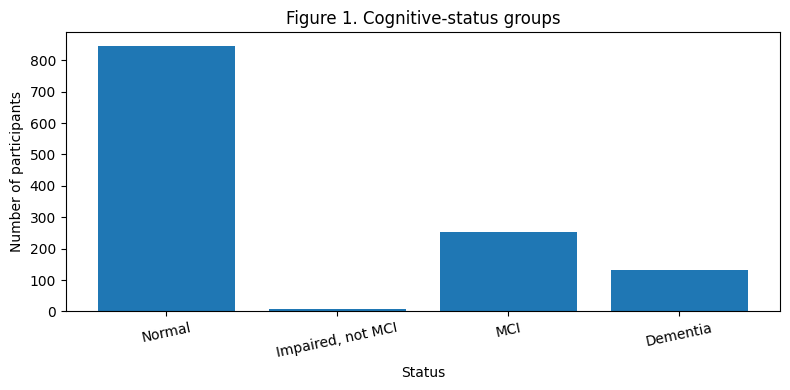

In [33]:
plt.bar(status_labels, status_counts.values)
plt.xticks(rotation=12)
plt.ylim(bottom=0)
plt.title('Figure 1. Cognitive-status groups')
plt.xlabel('Status')
plt.ylabel('Number of participants')
plt.tight_layout()
plt.show()

Draw Figure 2 directly from `score_counts`.

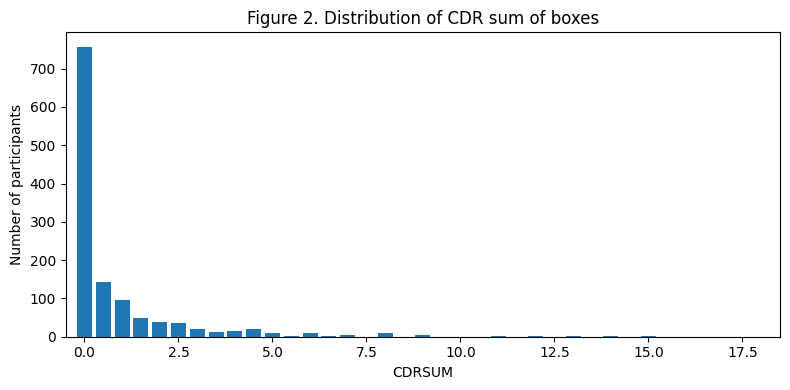

In [34]:
plt.bar(score_counts.index, score_counts.values, width=0.4)
plt.xlim(-0.5, 18.5)
plt.ylim(bottom=0)
plt.title('Figure 2. Distribution of CDR sum of boxes')
plt.xlabel('CDRSUM')
plt.ylabel('Number of participants')
plt.tight_layout()
plt.show()

Draw Figure 3 from bilateral thickness. The 24 bins only control the display, they do not change the sample or summary statistics.

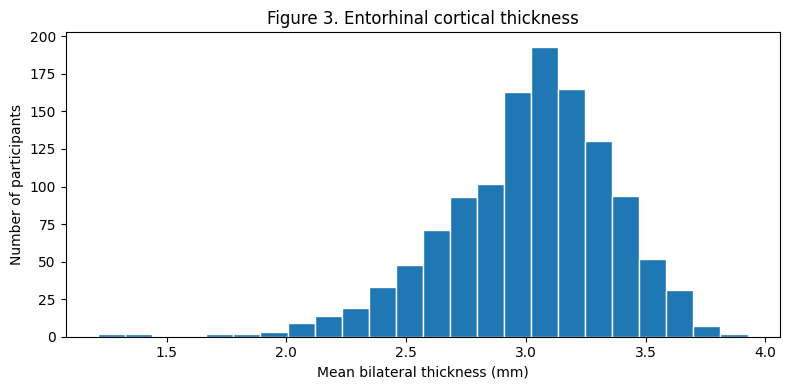

In [35]:
plt.hist(primary['entorhinal_mean_mm'], bins=24, edgecolor='white')
plt.title('Figure 3. Entorhinal cortical thickness')
plt.xlabel('Mean bilateral thickness (mm)')
plt.ylabel('Number of participants')
plt.tight_layout()
plt.show()

Split thickness values by the four status codes. These four groups become the inputs to the boxplot.

In [36]:
thickness_by_status = []
for status_code in status_codes:
    selected_people = primary['NACCUDSD'] == status_code
    group_values = primary.loc[selected_people, 'entorhinal_mean_mm']
    thickness_by_status.append(group_values)

Draw Figure 4 from the four groups prepared above. The thickness axis starts at zero.

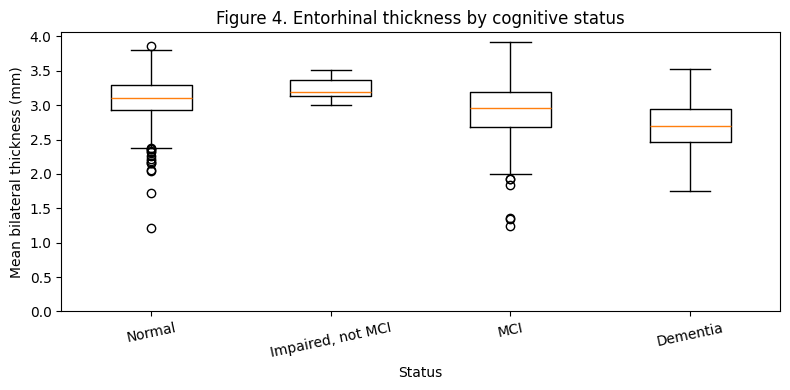

In [37]:
plt.boxplot(thickness_by_status)
plt.xticks([1, 2, 3, 4], status_labels, rotation=12)
plt.ylim(bottom=0)
plt.title('Figure 4. Entorhinal thickness by cognitive status')
plt.xlabel('Status')
plt.ylabel('Mean bilateral thickness (mm)')
plt.tight_layout()
plt.show()

## ۹. مقایسه‌ی توصیفی اولیه

Group participants by NACCUDSD and calculate their CDR/thickness summaries. Display labels do not change the group codes.

In [38]:
group_columns = ['CDRSUM', 'entorhinal_mean_mm']
group_summary = primary.groupby('NACCUDSD')[group_columns].agg(['count', 'mean', 'median', 'std'])
group_table = group_summary.copy()
group_table.index = status_labels
print('Table 7. Descriptive group comparison')
display(group_table)

Table 7. Descriptive group comparison


CDRSUM               ... entorhinal_mean_mm             
                   count  mean median  ...               mean median   std
Normal               847 0.102  0.000  ...              3.089  3.103 0.304
Impaired, not MCI      7 0.929  1.000  ...              3.243  3.188 0.182
MCI                  252 1.242  1.000  ...              2.908  2.966 0.413
Dementia             131 4.664  4.500  ...              2.719  2.691 0.355

[4 rows x 8 columns]

Subtract the normal-group mean from the dementia-group mean. Both values come from `group_summary`.

In [39]:
normal_mean = group_summary.loc[1, ('entorhinal_mean_mm', 'mean')]
dementia_mean = group_summary.loc[4, ('entorhinal_mean_mm', 'mean')]
mean_difference = dementia_mean - normal_mean
print(f'Dementia minus normal mean thickness: {mean_difference:.3f} mm')

Dementia minus normal mean thickness: -0.370 mm


## ج۱. نقشه‌ی زیرمجموعه‌ی UDS و MRI

Start a field-domain map. The following cells assign domains from the field definitions, they do not replace participant values.

In [40]:
column_groups = pd.Series('Medical', index=uds.columns)
column_groups.loc['NACCID'] = 'Identifier'
column_groups.loc['NACCUDSD'] = 'Clinical status'

Identify demographic columns by name. The next assignments handle functional and cognitive fields.

In [41]:
demographic_columns = ['SEX', 'HISPANIC', 'HISPOR', 'RACE', 'PRIMLANG', 'EDUC',
                       'MARISTAT', 'NACCLIVS', 'RESIDENC', 'NACCNIHR', 'NACCAGE']
column_groups.loc[demographic_columns] = 'Demographic'

Identify daily-function columns. This changes only the separate map, not `uds`.

In [42]:
functional_columns = ['INDEPEND', 'BILLS', 'TAXES', 'SHOPPING', 'GAMES', 'STOVE',
                      'MEALPREP', 'EVENTS', 'PAYATTN', 'REMDATES', 'TRAVEL']
column_groups.loc[functional_columns] = 'Functional'

Identify cognitive and clinical-rating columns, then count how many supplied fields belong to each domain.

In [43]:
cognitive_columns = ['DECSUB', 'ANIMALS', 'VEG', 'TRAILA', 'TRAILARR', 'TRAILALI',
                     'TRAILB', 'TRAILBRR', 'TRAILBLI', 'MOCATOTS', 'MEMORY', 'ORIENT',
                     'JUDGMENT', 'COMMUN', 'HOMEHOBB', 'PERSCARE', 'CDRSUM', 'CDRGLOB']
column_groups.loc[cognitive_columns] = 'Cognitive and clinical rating'
domain_counts = column_groups.value_counts().to_frame('Fields')
print('Table 8. UDS domains')
display(domain_counts)

Table 8. UDS domains


,Fields
Medical,138
Cognitive and clinical rating,18
Functional,11
Demographic,11
Identifier,1
Clinical status,1


Split existing MRI column names into hemisphere, region and measurement. AVGTH means thickness in mm, GVOL means volume in mm³.

In [44]:
mri_column_names = mri_fields.columns.to_series()
mri_map = mri_column_names.str.split('_', expand=True)
mri_map.columns = ['Hemisphere', 'Region', 'Measurement']
mri_map['Unit'] = np.where(mri_map['Measurement'] == 'AVGTH', 'mm', 'mm³')
print('MRI measurements:', len(mri_map))

MRI measurements: 124


Display the full maps built above so every supplied field can be traced to its meaning.

In [45]:
with pd.option_context('display.max_rows', None):
    display(column_groups.to_frame('UDS domain'))
    display(mri_map)

,UDS domain
NACCID,Identifier
SEX,Demographic
HISPANIC,Demographic
HISPOR,Demographic
RACE,Demographic
PRIMLANG,Demographic
EDUC,Demographic
MARISTAT,Demographic
NACCLIVS,Demographic
INDEPEND,Functional


,Hemisphere,Region,Measurement,Unit
LH_CAUDALANTERIORCINGULATE_GVOL,LH,CAUDALANTERIORCINGULATE,GVOL,mm³
RH_CAUDALANTERIORCINGULATE_GVOL,RH,CAUDALANTERIORCINGULATE,GVOL,mm³
LH_CAUDALANTERIORCINGULATE_AVGTH,LH,CAUDALANTERIORCINGULATE,AVGTH,mm
RH_CAUDALANTERIORCINGULATE_AVGTH,RH,CAUDALANTERIORCINGULATE,AVGTH,mm
LH_CAUDALMIDDLEFRONTAL_GVOL,LH,CAUDALMIDDLEFRONTAL,GVOL,mm³
RH_CAUDALMIDDLEFRONTAL_GVOL,RH,CAUDALMIDDLEFRONTAL,GVOL,mm³
LH_CAUDALMIDDLEFRONTAL_AVGTH,LH,CAUDALMIDDLEFRONTAL,AVGTH,mm
RH_CAUDALMIDDLEFRONTAL_AVGTH,RH,CAUDALMIDDLEFRONTAL,AVGTH,mm
LH_CUNEUS_GVOL,LH,CUNEUS,GVOL,mm³
RH_CUNEUS_GVOL,RH,CUNEUS,GVOL,mm³


## ج۵. خلاصه‌ی مشترک شناختی و تصویربرداری

Reuse the calculated statistics for CDR and the three thickness measures. No numbers are entered manually.

In [46]:
joint_columns = ['CDRSUM', left_thickness_column, right_thickness_column, 'entorhinal_mean_mm']
joint_summary = summary.loc[joint_columns, ['count', 'mean', '50%', 'std', 'min', 'max']]
print('Table 13. Joint clinical and MRI summary')
display(joint_summary)

Table 13. Joint clinical and MRI summary


,count,mean,50%,std,min,max
CDRSUM,1237.000,0.822,0.000,1.723,0.000,15.000
LH_ENTORHINAL_AVGTH,1237.000,2.970,3.021,0.384,0.878,3.979
RH_ENTORHINAL_AVGTH,1237.000,3.058,3.097,0.401,0.729,3.967
entorhinal_mean_mm,1237.000,3.014,3.058,0.356,1.214,3.925


Draw Figure 5 from paired values for the same participants.

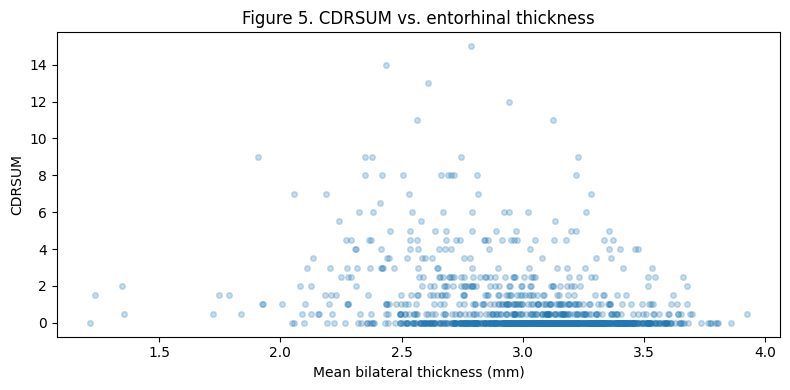

In [47]:
plt.scatter(primary['entorhinal_mean_mm'], primary['CDRSUM'], s=16, alpha=0.25)
plt.title('Figure 5. CDRSUM vs. entorhinal thickness')
plt.xlabel('Mean bilateral thickness (mm)')
plt.ylabel('CDRSUM')
plt.tight_layout()
plt.show()

Check that each participant is counted once and the calculated mean uses both hemispheres.

In [48]:
assert primary['NACCID'].is_unique
assert status_counts.sum() == len(primary)
calculated_mean = (primary[left_thickness_column] + primary[right_thickness_column]) / 2
assert np.allclose(primary['entorhinal_mean_mm'], calculated_mean)
print('Completed participants:', len(primary))

Completed participants: 1237
